# Analisis Karakteristik Aerodinamika dan Prediksi Tekanan Suara

**Tujuan**
1. Memprediksi tingkat tekanan suara (*Scaled Sound Pressure*, dB) dari parameter aerodinamika sayap (regresi).
2. Mengelompokkan kondisi pengujian dengan K-Means untuk melihat pola alami data (clustering).

**Dataset:** NASA Airfoil Self-Noise (UCI), 1503 baris, 5 fitur, 1 target.
| Kolom | Keterangan |
|---|---|
| Frequency | Frekuensi (Hz) |
| Angle_of_Attack | Sudut serang (derajat) |
| Chord_Length | Panjang chord (m) |
| Free_stream_Velocity | Kecepatan aliran bebas (m/s) |
| Suction_side_Displacement_Thickness | Ketebalan displacement sisi hisap (m) |
| Scaled_Sound_Pressure | **Target**, tekanan suara (dB) |

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import (train_test_split, KFold, cross_val_score, RandomizedSearchCV)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


## 2. Data Loading
File `.dat` dipisahkan tab dan tidak punya header, sehingga nama kolom diberikan manual.

In [2]:
kolom = [
    'Frequency',
    'Angle_of_Attack',
    'Chord_Length',
    'Free_stream_Velocity',
    'Suction_side_Displacement_Thickness',
    'Scaled_Sound_Pressure'
]

df = pd.read_csv('airfoil_self_noise.dat', sep=r'\s+', header=None, names=kolom)

display(df.head())
print("Ukuran dataset:", df.shape)

,Frequency,Angle_of_Attack,Chord_Length,Free_stream_Velocity,Suction_side_Displacement_Thickness,Scaled_Sound_Pressure
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


Ukuran dataset: (1503, 6)


## 3. Eksplorasi Data (EDA)

In [3]:
df.info()
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Frequency                            1503 non-null   int64  
 1   Angle_of_Attack                      1503 non-null   float64
 2   Chord_Length                         1503 non-null   float64
 3   Free_stream_Velocity                 1503 non-null   float64
 4   Suction_side_Displacement_Thickness  1503 non-null   float64
 5   Scaled_Sound_Pressure                1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB


,count,mean,std,min,25%,50%,75%,max
Frequency,1503.0,2886.380572,3152.573137,200.000000,800.000000,1600.000000,4000.000000,20000.000000
Angle_of_Attack,1503.0,6.782302,5.918128,0.000000,2.000000,5.400000,9.900000,22.200000
Chord_Length,1503.0,0.136548,0.093541,0.025400,0.050800,0.101600,0.228600,0.304800
Free_stream_Velocity,1503.0,50.860745,15.572784,31.700000,39.600000,39.600000,71.300000,71.300000
Suction_side_Displacement_Thickness,1503.0,0.011140,0.013150,0.000401,0.002535,0.004957,0.015576,0.058411
Scaled_Sound_Pressure,1503.0,124.835943,6.898657,103.380000,120.191000,125.721000,129.995500,140.987000


### 3.1 Pemeriksaan Kualitas Data

In [4]:
print("Missing values per kolom:")
print(df.isnull().sum())
print("\nBaris duplikat:", df.duplicated().sum())
print("Nilai tak terhingga:", int(np.isinf(df).sum().sum()))

print("\nJumlah nilai unik per kolom:")
print(df.nunique())

Missing values per kolom:
Frequency                              0
Angle_of_Attack                        0
Chord_Length                           0
Free_stream_Velocity                   0
Suction_side_Displacement_Thickness    0
Scaled_Sound_Pressure                  0
dtype: int64

Baris duplikat: 0
Nilai tak terhingga: 0

Jumlah nilai unik per kolom:
Frequency                                21
Angle_of_Attack                          27
Chord_Length                              6
Free_stream_Velocity                      4
Suction_side_Displacement_Thickness     105
Scaled_Sound_Pressure                  1456
dtype: int64


Tidak ada missing value, duplikat, maupun nilai tak terhingga, jadi tidak perlu imputasi atau penghapusan baris. Jumlah nilai unik pada `Chord_Length` (6) dan `Free_stream_Velocity` (4) sangat sedikit. Hal ini wajar karena data berasal dari eksperimen terowongan angin dengan konfigurasi diskret, dan akan memengaruhi hasil clustering.

### 3.2 Distribusi Variabel

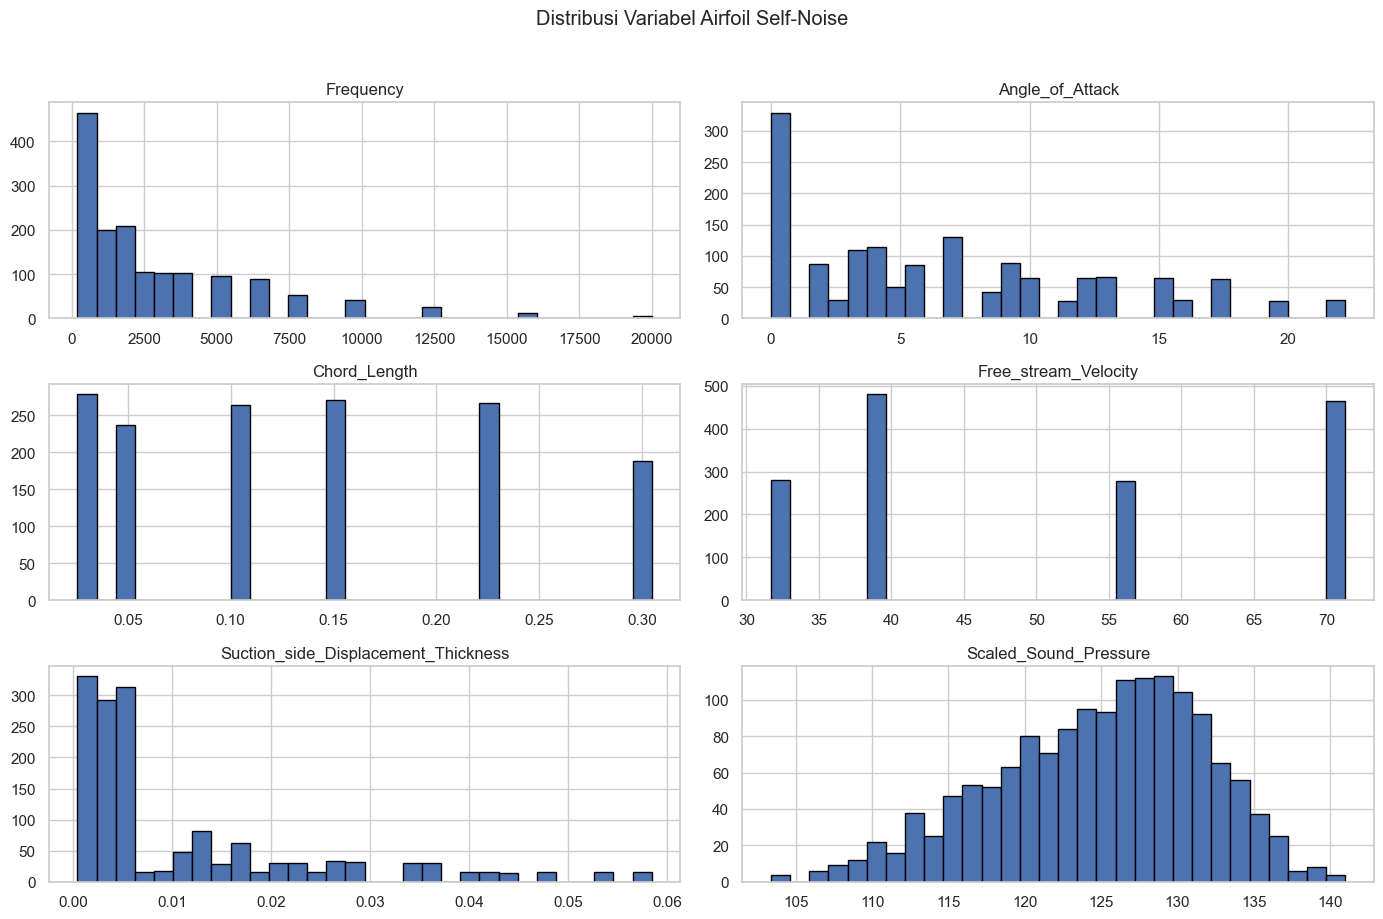

In [5]:
df.hist(figsize=(14, 9), bins=30, edgecolor='black')
plt.suptitle("Distribusi Variabel Airfoil Self-Noise", y=1.02)
plt.tight_layout()
plt.show()

### 3.3 Boxplot per Variabel
Setiap variabel diplot di sumbu sendiri karena skalanya sangat berbeda.

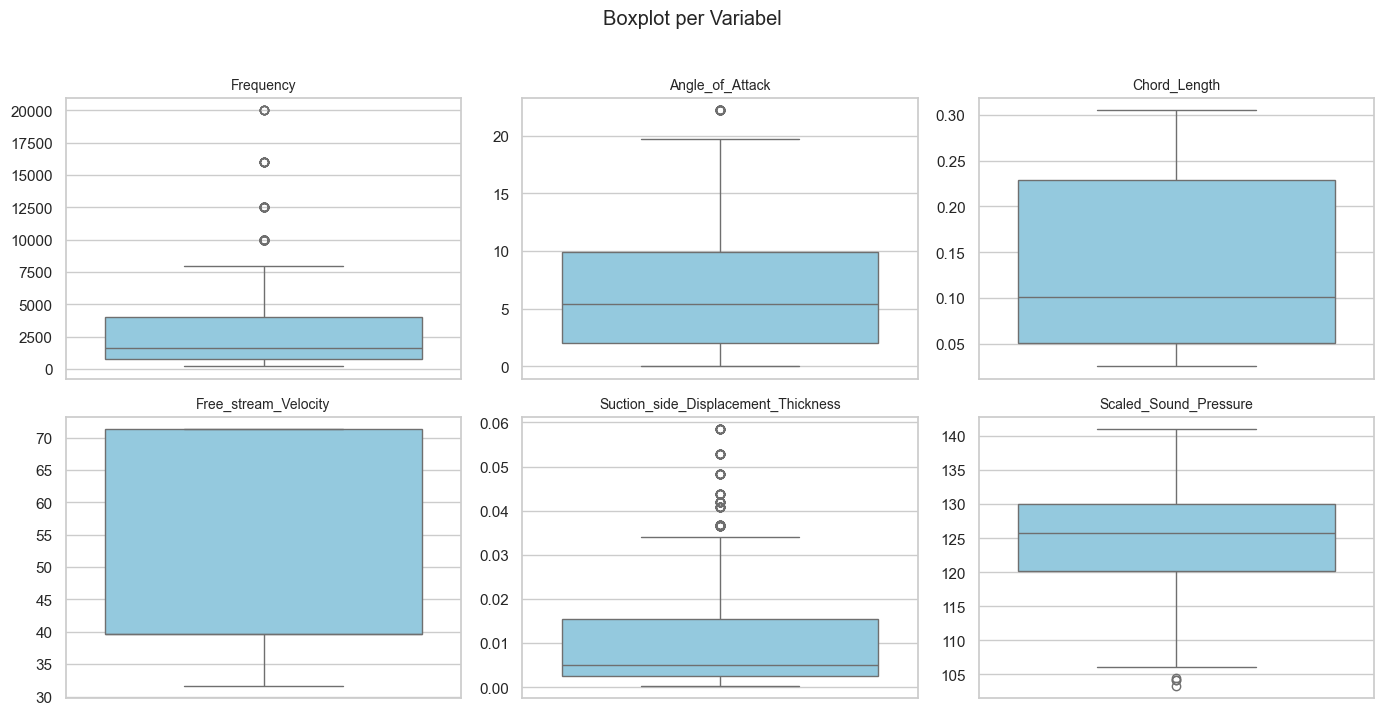

Jumlah outlier (IQR):
Frequency                               86
Angle_of_Attack                         30
Chord_Length                             0
Free_stream_Velocity                     0
Suction_side_Displacement_Thickness    124
Scaled_Sound_Pressure                    4
dtype: int64


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), df.columns):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
plt.suptitle("Boxplot per Variabel", y=1.02)
plt.tight_layout()
plt.show()

# Jumlah outlier menurut aturan IQR (1.5 x IQR)
hasil = {}
for col in df.columns:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    hasil[col] = int(((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum())
print("Jumlah outlier (IQR):")
print(pd.Series(hasil))

Outlier tidak dihapus. Nilai-nilai tersebut adalah hasil pengukuran eksperimen yang sah (misalnya frekuensi tinggi atau sayap dengan ketebalan displacement besar), bukan kesalahan input.

### 3.4 Analisis Hubungan Fitur dengan Target

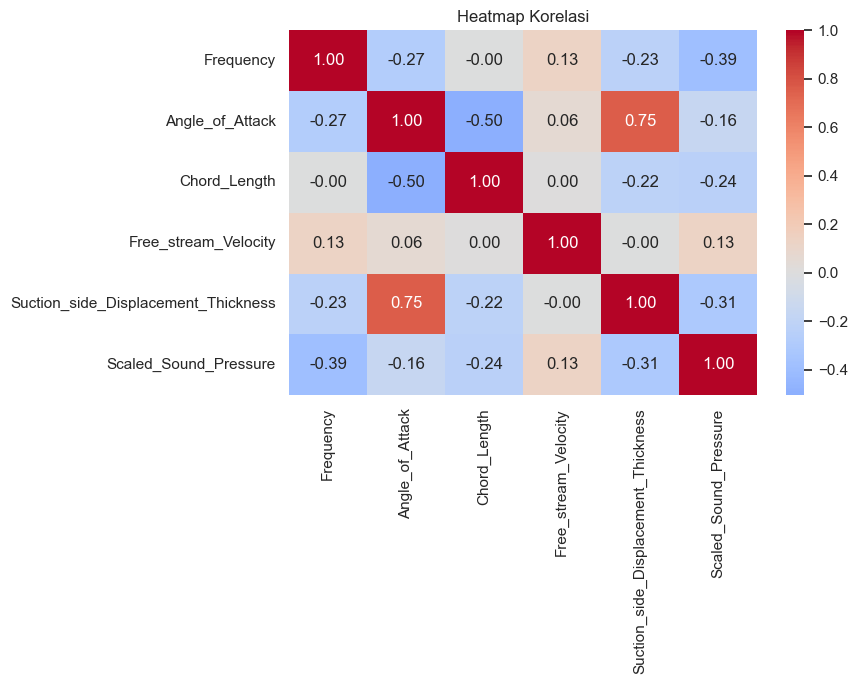

Korelasi terhadap target:
Frequency                             -0.391
Suction_side_Displacement_Thickness   -0.313
Chord_Length                          -0.236
Angle_of_Attack                       -0.156
Free_stream_Velocity                   0.125
Name: Scaled_Sound_Pressure, dtype: float64


In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title("Heatmap Korelasi")
plt.tight_layout()
plt.show()

print("Korelasi terhadap target:")
print(df.corr()['Scaled_Sound_Pressure'].drop('Scaled_Sound_Pressure')
        .sort_values(key=abs, ascending=False).round(3))

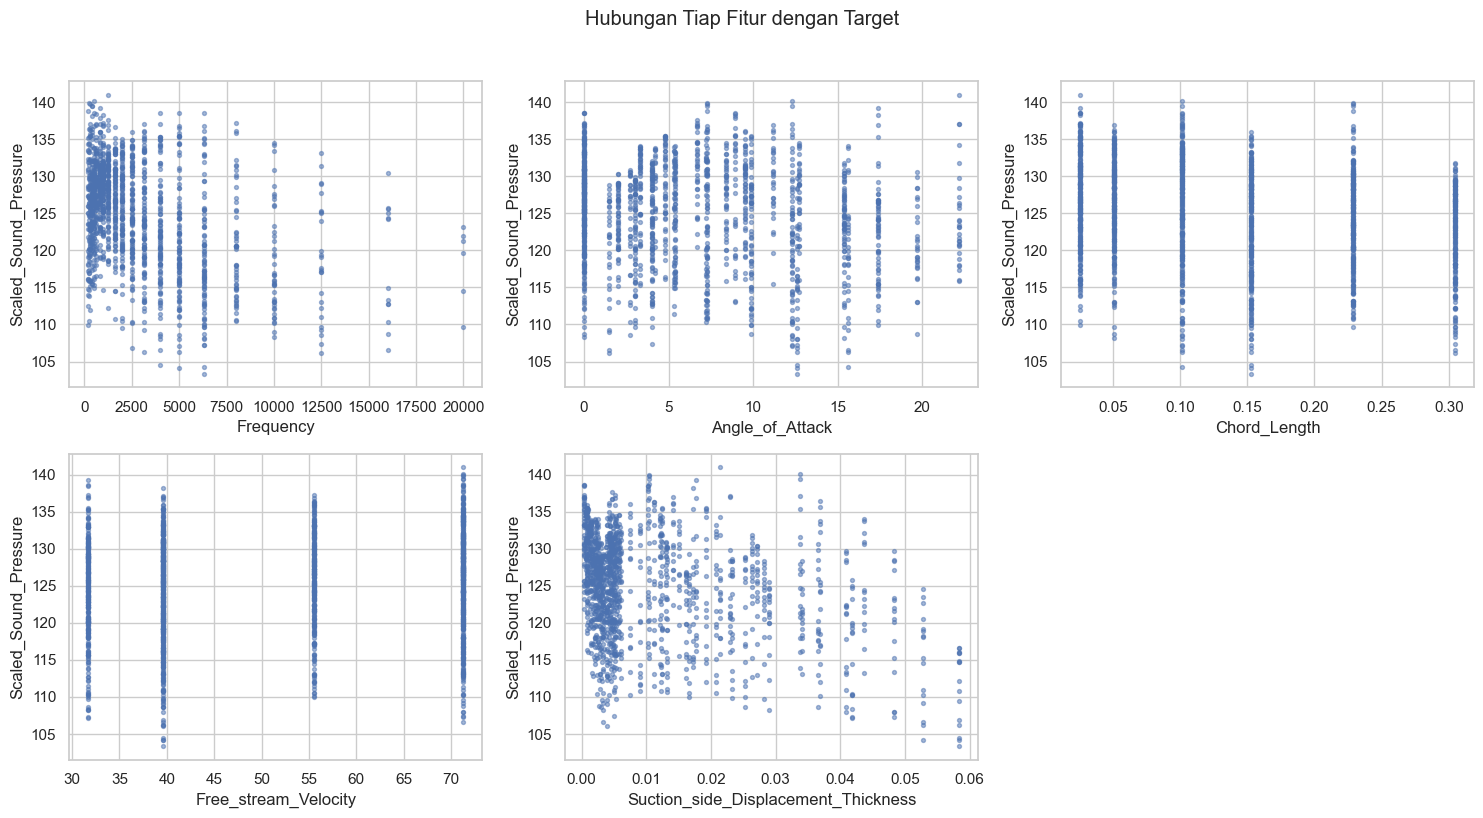

In [8]:
fitur = ['Frequency', 'Angle_of_Attack', 'Chord_Length',
         'Free_stream_Velocity', 'Suction_side_Displacement_Thickness']
target = 'Scaled_Sound_Pressure'

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), fitur):
    ax.scatter(df[f], df[target], s=8, alpha=.5)
    ax.set_xlabel(f); ax.set_ylabel(target)
axes.ravel()[-1].axis('off')
plt.suptitle("Hubungan Tiap Fitur dengan Target", y=1.02)
plt.tight_layout()
plt.show()

Korelasi linear tiap fitur terhadap target tergolong lemah sampai sedang (maksimum sekitar 0,39), dan sebaran titik menunjukkan hubungan yang **nonlinear**. Model linear akan kesulitan, sedangkan model berbasis pohon diperkirakan jauh lebih baik. Hal ini diuji pada bagian 6.

## 4. Preprocessing Data
Data dibagi **sebelum** langkah lain yang mempelajari statistik data agar tidak terjadi *data leakage*. Rasio pembagian 80% latih dan 20% uji.

In [9]:
X = df[fitur]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (1202, 5) | Data uji: (301, 5)


## 5. Clustering dengan K-Means (Analisis Eksploratif)
Clustering bersifat tanpa label (*unsupervised*) sehingga dijalankan pada seluruh fitur yang sudah distandardisasi. Target **tidak** dipakai. K ditentukan dengan Elbow Method dan Silhouette Score.

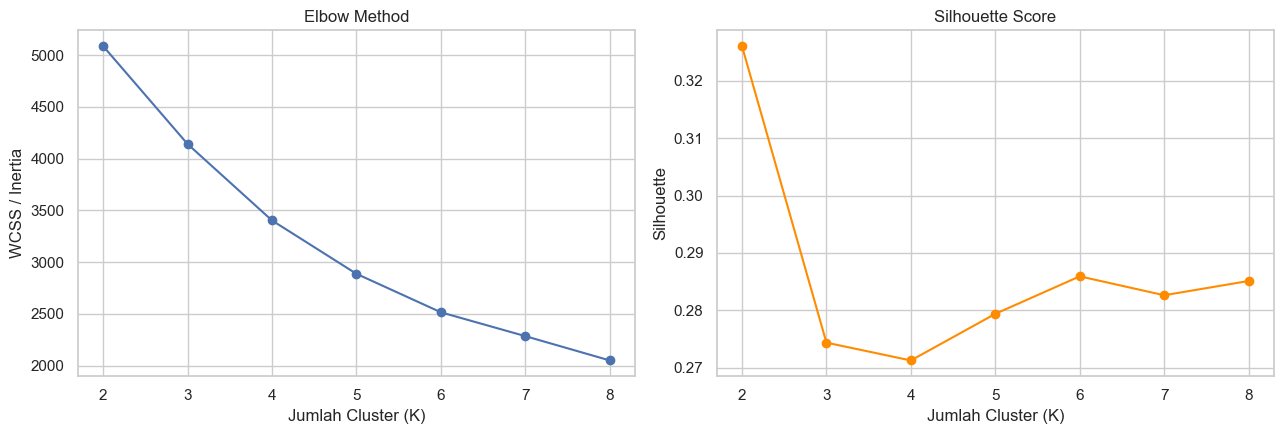

,K,WCSS,Silhouette
0,2,5088.9,0.3261
1,3,4142.1,0.2744
2,4,3402.9,0.2713
3,5,2887.1,0.2794
4,6,2514.9,0.2859
5,7,2284.5,0.2826
6,8,2049.4,0.2851


In [10]:
scaler_all = StandardScaler()
X_scaled = scaler_all.fit_transform(X)

ks = range(2, 9)
wcss, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(ks), wcss, marker='o')
ax[0].set(title="Elbow Method", xlabel="Jumlah Cluster (K)", ylabel="WCSS / Inertia")
ax[1].plot(list(ks), sil, marker='o', color='darkorange')
ax[1].set(title="Silhouette Score", xlabel="Jumlah Cluster (K)", ylabel="Silhouette")
for a in ax: a.set_xticks(list(ks))
plt.tight_layout()
plt.show()

display(pd.DataFrame({'K': list(ks), 'WCSS': np.round(wcss, 1), 'Silhouette': np.round(sil, 4)}))

In [11]:
K_TERBAIK = list(ks)[int(np.argmax(sil))]
print("K dengan silhouette tertinggi:", K_TERBAIK)

kmeans = KMeans(n_clusters=K_TERBAIK, random_state=RANDOM_STATE, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nSilhouette Score:", round(silhouette_score(X_scaled, df['Cluster']), 4))
print("\nJumlah data per cluster:")
print(df['Cluster'].value_counts().sort_index())

K dengan silhouette tertinggi: 2

Silhouette Score: 0.3261

Jumlah data per cluster:
Cluster
0    1066
1     437
Name: count, dtype: int64


### 5.1 Profil Tiap Cluster

In [12]:
profil = df.groupby('Cluster')[fitur + [target]].mean().round(4)
profil['Jumlah'] = df['Cluster'].value_counts().sort_index()
display(profil)

,Frequency,Angle_of_Attack,Chord_Length,Free_stream_Velocity,Suction_side_Displacement_Thickness,Scaled_Sound_Pressure,Jumlah
Cluster,,,,,,,
0,3305.5535,3.6130,0.1612,50.3800,0.0041,125.7372,1066
1,1863.8673,14.5133,0.0764,52.0334,0.0283,122.6375,437


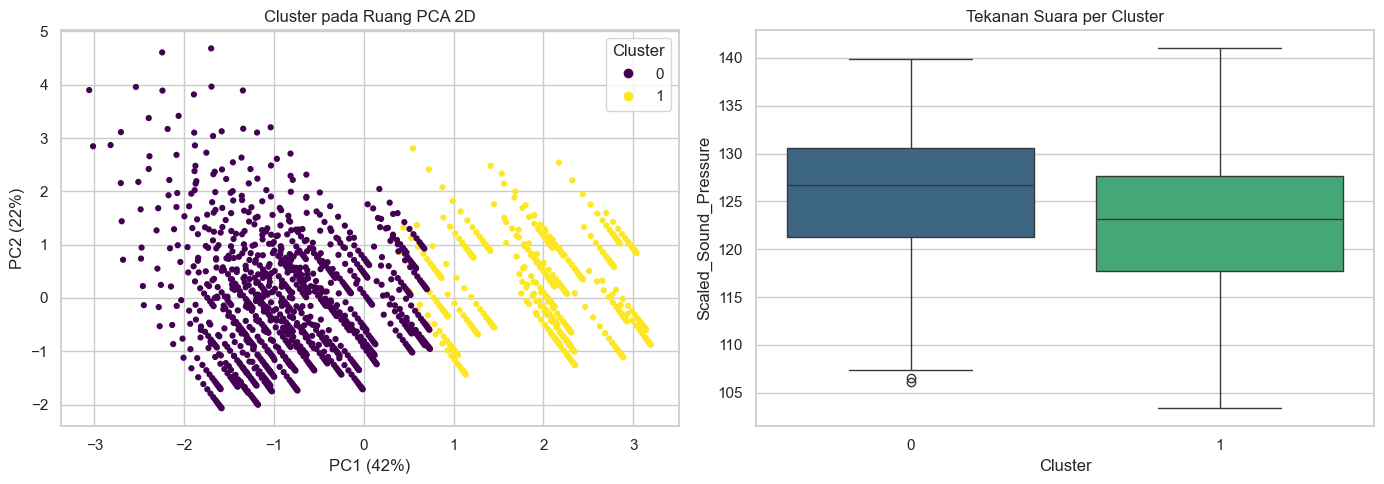

In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
komp = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sc = ax[0].scatter(komp[:, 0], komp[:, 1], c=df['Cluster'], cmap='viridis', s=12)
ax[0].set(title="Cluster pada Ruang PCA 2D",
          xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax[0].legend(*sc.legend_elements(), title="Cluster")

sns.boxplot(
    data=df,
    x='Cluster',
    y=target,
    hue='Cluster',
    palette='viridis',
    legend=False,
    ax=ax[1])
ax[1].set_title("Tekanan Suara per Cluster")
plt.tight_layout()
plt.show()

Silhouette tertinggi dicapai pada K=2 (sekitar 0,33), dan nilainya turun ke kisaran 0,27 sampai 0,29 untuk K lebih besar. Ini berarti struktur cluster **lemah dan saling tumpang tindih**. Jumlah cluster dipilih berdasarkan silhouette tertinggi, dan hasil elbow tidak menunjukkan siku yang tegas sehingga tidak dipakai sebagai penentu tunggal. Ini wajar karena fitur seperti `Chord_Length` dan `Free_stream_Velocity` hanya punya sedikit nilai diskret, sehingga data lebih bersifat "kombinasi konfigurasi eksperimen" daripada kelompok alami.

## 6. Pemodelan Regresi
### 6.1 Perbandingan Beberapa Model (Cross-Validation pada Data Latih)
Model dibandingkan dengan 5-fold cross-validation pada **data latih saja**. Data uji disimpan untuk evaluasi akhir. Model linear dan K-Means butuh scaling, sehingga dibungkus `Pipeline` agar scaler hanya di-*fit* pada fold latih.

In [14]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

kandidat = {
    "Linear Regression": Pipeline([('sc', StandardScaler()), ('m', LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

baris = []
for nama, model in kandidat.items():
    r2_cv = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
    rmse_cv = -cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    baris.append({'Model': nama, 'R2 CV (rata-rata)': r2_cv.mean(),
                  'R2 CV (std)': r2_cv.std(), 'RMSE CV': rmse_cv.mean()})

hasil_cv = pd.DataFrame(baris).sort_values('R2 CV (rata-rata)', ascending=False).round(4)
display(hasil_cv.reset_index(drop=True))

,Model,R2 CV (rata-rata),R2 CV (std),RMSE CV
0,Random Forest,0.9183,0.0126,1.9401
1,Gradient Boosting,0.8328,0.0320,2.7744
2,Decision Tree,0.8303,0.0352,2.7939
3,Linear Regression,0.4922,0.0738,4.8467


Regresi Linear jauh tertinggal dibanding model berbasis pohon, yang mengonfirmasi dugaan hubungan nonlinear pada EDA. Random Forest unggul jelas atas Decision Tree tunggal karena menggabungkan banyak pohon sehingga lebih stabil, sedangkan Gradient Boosting dengan pengaturan bawaan setara dengan Decision Tree.

### 6.2 Tuning Hyperparameter Random Forest

In [15]:
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 15, 20, 30],
    'min_samples_split': [2, 4, 6],
    'min_samples_leaf': [1, 2, 3],
    'max_features': [1.0, 'sqrt', 0.6],
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=25, cv=kf, scoring='r2',
    random_state=RANDOM_STATE, n_jobs=-1
)
search.fit(X_train, y_train)

print(search.best_params_)
print("R2 CV:", round(search.best_score_, 4))

{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': None}
R2 CV: 0.917


### 6.3 Evaluasi Akhir pada Data Uji

In [16]:
def evaluasi(nama, model):
    pred = model.predict(X_test)
    return {'Model': nama,
            'MAE': mean_absolute_error(y_test, pred),
            'MSE': mean_squared_error(y_test, pred),
            'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
            'R2': r2_score(y_test, pred)}

lr = kandidat["Linear Regression"].fit(X_train, y_train)
rf_default = kandidat["Random Forest"].fit(X_train, y_train)
rf_tuned = search.best_estimator_

tabel = pd.DataFrame([
    evaluasi("Linear Regression (baseline)", lr),
    evaluasi("Random Forest (default)", rf_default),
    evaluasi("Random Forest (tuned)", rf_tuned),
]).round(4)
display(tabel)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression (baseline),3.6724,22.1286,4.7041,0.5583
1,Random Forest (default),1.3119,3.2787,1.8107,0.9346
2,Random Forest (tuned),1.2789,3.1207,1.7666,0.9377


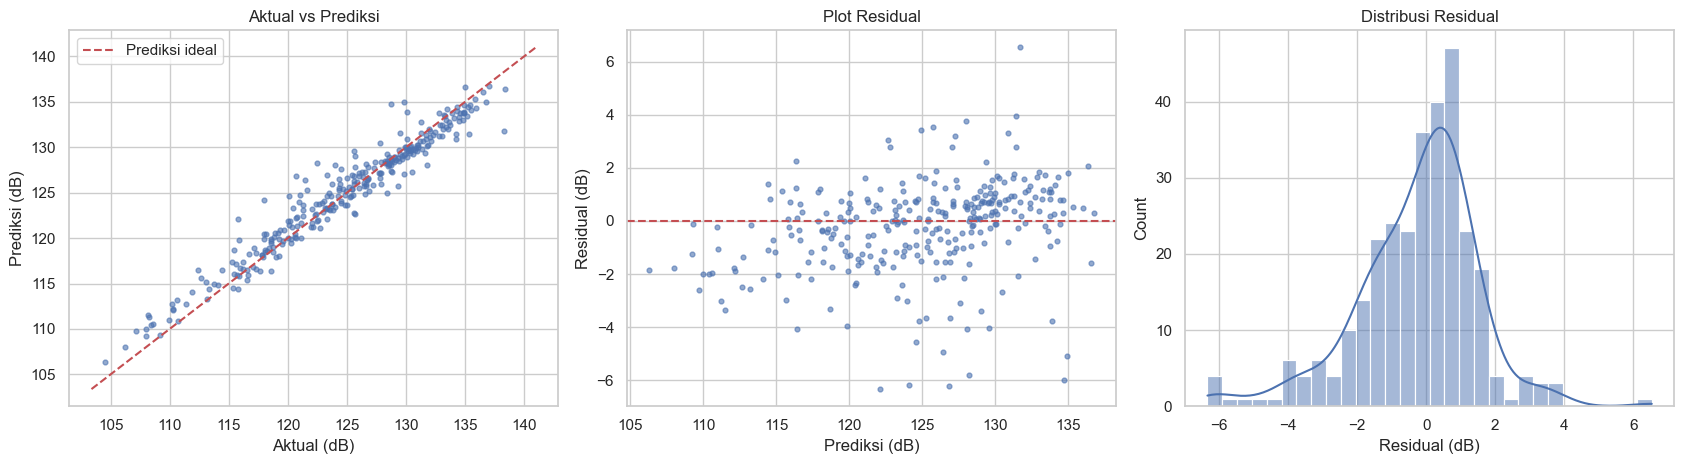

In [17]:
y_pred = rf_tuned.predict(X_test)
residual = y_test - y_pred

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

ax[0].scatter(y_test, y_pred, s=12, alpha=.6)
lim = [y.min(), y.max()]
ax[0].plot(lim, lim, 'r--', label='Prediksi ideal')
ax[0].set(title="Aktual vs Prediksi", xlabel="Aktual (dB)", ylabel="Prediksi (dB)")
ax[0].legend()

ax[1].scatter(y_pred, residual, s=12, alpha=.6)
ax[1].axhline(0, color='r', linestyle='--')
ax[1].set(title="Plot Residual", xlabel="Prediksi (dB)", ylabel="Residual (dB)")

sns.histplot(residual, bins=30, kde=True, ax=ax[2])
ax[2].set(title="Distribusi Residual", xlabel="Residual (dB)")

plt.tight_layout()
plt.show()

Titik aktual vs prediksi rapat di sekitar garis diagonal, residual tersebar acak di sekitar nol tanpa pola yang jelas, dan distribusinya mendekati simetris. Hal ini menunjukkan model tidak bias secara sistematis.

## 7. Bobot Fitur

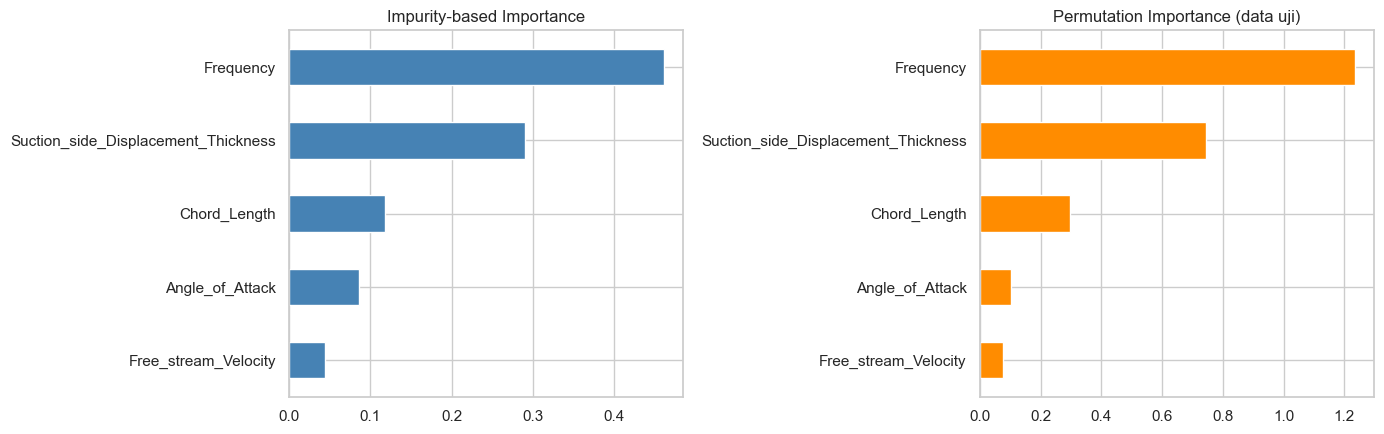

,Impurity,Permutation
Frequency,0.4616,1.2358
Suction_side_Displacement_Thickness,0.2905,0.7428
Chord_Length,0.1180,0.2953
Angle_of_Attack,0.0857,0.1024
Free_stream_Velocity,0.0442,0.0748


In [18]:
imp_bawaan = pd.Series(rf_tuned.feature_importances_, index=fitur)
perm = permutation_importance(rf_tuned, X_test, y_test, n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=fitur)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
imp_bawaan.sort_values().plot.barh(ax=ax[0], color='steelblue')
ax[0].set_title("Impurity-based Importance")
imp_perm.sort_values().plot.barh(ax=ax[1], color='darkorange')
ax[1].set_title("Permutation Importance (data uji)")
plt.tight_layout()
plt.show()

display(pd.DataFrame({'Impurity': imp_bawaan, 'Permutation': imp_perm}).round(4)
          .sort_values('Permutation', ascending=False))

## 8. Eksperimen: Apakah Label Cluster Membantu Regresi?
Untuk menghubungkan bagian clustering dengan regresi, label cluster ditambahkan sebagai fitur. Agar tidak terjadi *data leakage*, scaler dan K-Means di-*fit* **hanya pada data latih**, lalu diterapkan ke data uji.

In [19]:
sc = StandardScaler().fit(X_train)
km = KMeans(n_clusters=K_TERBAIK, random_state=RANDOM_STATE, n_init=10).fit(sc.transform(X_train))

X_train_c = X_train.copy(); X_test_c = X_test.copy()
X_train_c['Cluster'] = km.predict(sc.transform(X_train))
X_test_c['Cluster'] = km.predict(sc.transform(X_test))

rf_c = RandomForestRegressor(**{**rf_tuned.get_params()}).fit(X_train_c, y_train)
pred_c = rf_c.predict(X_test_c)

pembanding = pd.DataFrame([
    {'Skenario': 'Tanpa fitur Cluster', 'MAE': mean_absolute_error(y_test, y_pred),
     'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)), 'R2': r2_score(y_test, y_pred)},
    {'Skenario': 'Dengan fitur Cluster', 'MAE': mean_absolute_error(y_test, pred_c),
     'RMSE': np.sqrt(mean_squared_error(y_test, pred_c)), 'R2': r2_score(y_test, pred_c)},
]).round(4)
display(pembanding)

,Skenario,MAE,RMSE,R2
0,Tanpa fitur Cluster,1.2789,1.7666,0.9377
1,Dengan fitur Cluster,1.2798,1.7525,0.9387


## 9. Kesimpulan

In [20]:
terbaik = tabel.iloc[2]
print(f"Model akhir : Random Forest (tuned)")
print(f"R2 uji      : {terbaik['R2']:.4f}")
print(f"MAE uji     : {terbaik['MAE']:.4f} dB")
print(f"RMSE uji    : {terbaik['RMSE']:.4f} dB")
print(f"Baseline LR : R2 = {tabel.iloc[0]['R2']:.4f}")
print("Fitur paling berpengaruh:", ", ".join(imp_perm.sort_values(ascending=False).index[:2]))

Model akhir : Random Forest (tuned)
R2 uji      : 0.9377
MAE uji     : 1.2789 dB
RMSE uji    : 1.7666 dB
Baseline LR : R2 = 0.5583
Fitur paling berpengaruh: Frequency, Suction_side_Displacement_Thickness


1. **Kualitas data baik:** tidak ada missing value maupun duplikat, dan outlier dipertahankan karena merupakan data eksperimen yang sah.
2. **Hubungan bersifat nonlinear:** Regresi Linear hanya mencapai R² sekitar 0,56, sedangkan model berbasis pohon mencapai sekitar 0,83 sampai 0,92 pada cross-validation. Random Forest yang sudah di-tuning mencapai R² sekitar 0,93 pada data uji, dengan kesalahan rata-rata sekitar 1,3 dB.
3. **Fitur dominan:** `Frequency` dan `Suction_side_Displacement_Thickness` paling berpengaruh terhadap tingkat kebisingan.
4. **Clustering:** struktur cluster lemah (silhouette sekitar 0,33 pada K=2) karena fitur bersifat diskret hasil konfigurasi eksperimen. Clustering cukup informatif sebagai eksplorasi, tetapi tidak meningkatkan akurasi prediksi.